In [1]:
"""
APPM 4370/5370 HW4, Problem 3(c): Hopfield network capacity, N = 500.

Network:  s_i <- sgn(h_i),   h_i = sum_j W_ij s_j,   sgn(0) = +1
Hebb rule: W_ij = (1/N) sum_mu xi_i^mu xi_j^mu,  W_ii = 0
"""
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt


N = 500                                  # number of units
alphas = [0.02, 0.06, 0.10, 0.14, 0.18, 0.22, 0.26, 0.30,
          0.34, 0.38, 0.42, 0.46, 0.50, 0.54, 0.58, 0.62]
n_cues = 10                              # recall tests per alpha
n_flip = 50                              # 10% of 500 bits flipped in each cue

rng = np.random.default_rng(4370)



def hebb_weights(patterns):
    # (patterns @ patterns.T)[i, j] = sum over mu of xi_i^mu * xi_j^mu, which is exactly the Hebb sum
    W = patterns @ patterns.T / N
    np.fill_diagonal(W, 0.0)             # no self-connections
    return W


def recall(W, s):
    s = s.copy()
    h = W @ s                            # local fields h_i = sum_j W_ij s_j
    while True:
        n_changed = 0
        for i in rng.permutation(N):     # visit every unit once, in random order
            new_value = 1.0 if h[i] >= 0 else -1.0       # s_i <- sgn(h_i), sgn(0) = +1
            if new_value != s[i]:
                h = h + (new_value - s[i]) * W[:, i]     # s_i changed, so every h_k changes by W_ki * (change)
                s[i] = new_value
                n_changed += 1
        if n_changed == 0:               # a whole sweep with no flips: fixed point
            return s




In [2]:

unstable_sim = []        # measured fraction of unstable bits
unstable_theory = []     # Phi(-1/sqrt(alpha)) from part (b)
mean_overlap = []        # <m> over the 10 cues
overlap_error = []       # standard error of <m>

for alpha in alphas:
    P = int(round(alpha * N))

    # random patterns: column mu is pattern xi^mu, each entry +1 or -1
    patterns = rng.choice([-1.0, 1.0], size=(N, P))
    W = hebb_weights(patterns)

    # bit stability: is xi_i^mu * h_i^mu < 0 when the network sits at pattern mu? ---
    H = W @ patterns                     # column mu of H = fields h_i when the network sits at pattern mu
    unstable = patterns * H < 0          # True where xi_i^mu * h_i^mu < 0 (bit would flip)
    frac_unstable = unstable.mean()      # fraction of all N*P bits that are unstable

    # 
    cue_patterns = rng.choice(P, size=n_cues, replace=False)   # which stored patterns to test
    overlaps = []
    for mu in cue_patterns:
        xi = patterns[:, mu]
        cue = xi.copy()
        flip_these = rng.choice(N, size=n_flip, replace=False)
        cue[flip_these] = -cue[flip_these]                     # corrupt 10% of the bits

        s_final = recall(W, cue)
        m = np.dot(xi, s_final) / N                            # overlap m = (1/N) xi . s
        overlaps.append(m)
    overlaps = np.array(overlaps)

    # store results
    unstable_sim.append(frac_unstable)
    unstable_theory.append(norm.cdf(-1 / np.sqrt(alpha)))
    mean_overlap.append(overlaps.mean())
    overlap_error.append(overlaps.std(ddof=1) / np.sqrt(n_cues))

    n_success = np.sum(overlaps > 0.95)
    print(f"alpha = {alpha:.2f}, P = {P:3d}: unstable {frac_unstable:.5f} (theory {unstable_theory[-1]:.5f}), "
          f"<m> = {overlaps.mean():.4f} +- {overlap_error[-1]:.4f}, recalled {n_success}/{n_cues}")

# part (b) numbers
alpha_1pct = 1 / norm.ppf(0.01)**2       # solves Phi(-1/sqrt(alpha)) = 0.01
print(f"alpha where 1% of bits are unstable: {alpha_1pct:.4f}")
print(f"N / (2 ln N) = {N / (2 * np.log(N)):.1f} patterns")



alpha = 0.02, P =  10: unstable 0.00000 (theory 0.00000), <m> = 1.0000 +- 0.0000, recalled 10/10
alpha = 0.06, P =  30: unstable 0.00000 (theory 0.00002), <m> = 1.0000 +- 0.0000, recalled 10/10
alpha = 0.10, P =  50: unstable 0.00068 (theory 0.00078), <m> = 0.9956 +- 0.0040, recalled 10/10
alpha = 0.14, P =  70: unstable 0.00351 (theory 0.00376), <m> = 0.8964 +- 0.0684, recalled 8/10
alpha = 0.18, P =  90: unstable 0.00847 (theory 0.00921), <m> = 0.4840 +- 0.0679, recalled 1/10
alpha = 0.22, P = 110: unstable 0.01607 (theory 0.01650), <m> = 0.4260 +- 0.0349, recalled 0/10
alpha = 0.26, P = 130: unstable 0.02614 (theory 0.02493), <m> = 0.4108 +- 0.0326, recalled 0/10
alpha = 0.30, P = 150: unstable 0.03293 (theory 0.03394), <m> = 0.2776 +- 0.0437, recalled 0/10
alpha = 0.34, P = 170: unstable 0.04309 (theory 0.04317), <m> = 0.3228 +- 0.0402, recalled 0/10
alpha = 0.38, P = 190: unstable 0.05224 (theory 0.05238), <m> = 0.2648 +- 0.0322, recalled 0/10
alpha = 0.42, P = 210: unstable 0.060

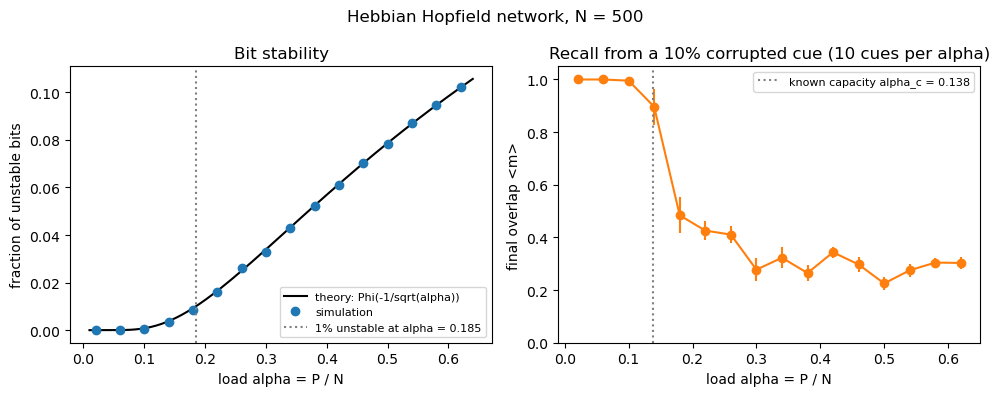

In [3]:
alpha_fine = np.linspace(0.01, 0.64, 300)

plt.figure(figsize=(10, 4))

# left panel: fraction of unstable bits
plt.subplot(1, 2, 1)
plt.plot(alpha_fine, norm.cdf(-1 / np.sqrt(alpha_fine)), color="black", label="theory: Phi(-1/sqrt(alpha))")
plt.plot(alphas, unstable_sim, "o", color="tab:blue", label="simulation")
plt.axvline(alpha_1pct, color="gray", linestyle=":", label=f"1% unstable at alpha = {alpha_1pct:.3f}")
plt.xlabel("load alpha = P / N")
plt.ylabel("fraction of unstable bits")
plt.title("Bit stability")
plt.legend(fontsize=8)

# right panel: recall quality
plt.subplot(1, 2, 2)
plt.errorbar(alphas, mean_overlap, yerr=overlap_error, fmt="o-", color="tab:orange")
plt.axvline(0.138, color="gray", linestyle=":", label="known capacity alpha_c = 0.138")
plt.ylim(0, 1.05)
plt.xlabel("load alpha = P / N")
plt.ylabel("final overlap <m>")
plt.title("Recall from a 10% corrupted cue (10 cues per alpha)")
plt.legend(fontsize=8)

plt.suptitle(f"Hebbian Hopfield network, N = {N}")
plt.tight_layout()
plt.show()